In [2]:
import pandas as pd

In [3]:
df_items= pd.read_csv('items.csv')
df_items.head()

,id,store_id,name,kcal,cost
0,1,4,Chocolate Cake,554,6.71
1,2,4,Breaded Fish with Vegetables Meal,772,15.09
2,3,1,Sweet Fruity Cake,931,29.22
3,4,1,Amazing Steak Dinner with Rolls,763,26.42
4,5,5,Milk Cake,583,6.07


In [4]:
df_resturants= pd.read_csv('resturants.csv')
df_resturants.head()

,id,name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack
3,4,Fou Cher
4,5,Corner Cafe


In [5]:
df_sales= pd.read_csv('sales.csv')
df_sales.head()

,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0


In [6]:
print(df_sales.shape)
print(df_resturants.shape)
print(df_items.shape)

(109600, 4)
(6, 2)
(100, 5)


In [7]:
df_sales.describe()

,item_id,price,item_count
count,109600.000000,109600.000000,109600.000000
mean,50.500000,11.763700,6.339297
std,28.866202,8.946225,30.003728
min,1.000000,1.390000,0.000000
25%,25.750000,5.280000,0.000000
50%,50.500000,7.625000,0.000000
75%,75.250000,18.790000,0.000000
max,100.000000,53.980000,570.000000


In [8]:
df_items.describe()

,id,store_id,kcal,cost
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,3.520000,536.730000,11.763700
std,29.011492,1.708446,202.212852,8.991254
min,1.000000,1.000000,78.000000,1.390000
25%,25.750000,2.000000,406.250000,5.280000
50%,50.500000,4.000000,572.500000,7.625000
75%,75.250000,5.000000,638.250000,18.790000
max,100.000000,6.000000,1023.000000,53.980000


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

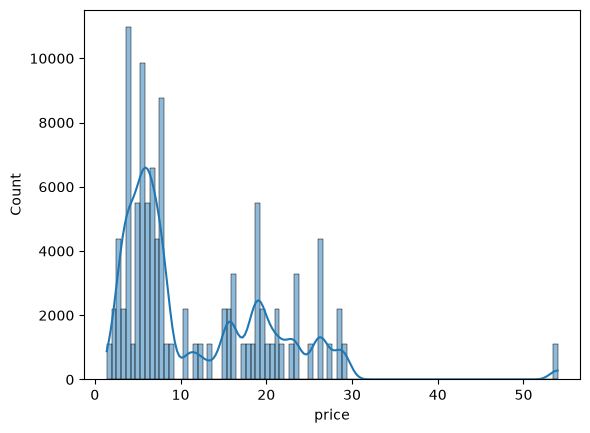

In [10]:
sns.histplot(df_sales['price'], kde=True)
plt.show()

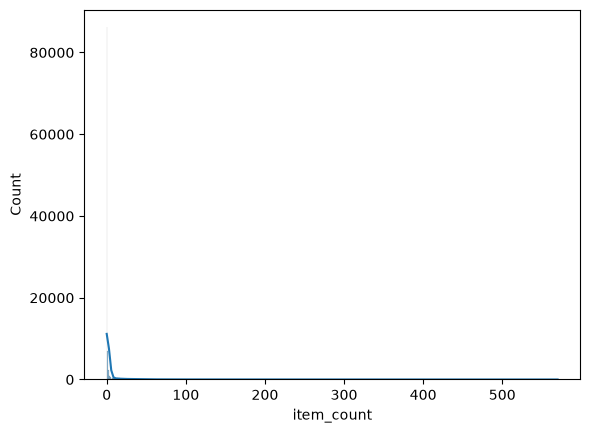

In [11]:
sns.histplot(df_sales['item_count'], kde=True)
plt.show()

In [12]:
q80= df_sales['item_count'].quantile(0.90)
print(q80)

7.0


In [13]:
q60= df_sales['item_count'].quantile(0.60)
print(q60)

0.0


In [14]:
q70= df_sales['item_count'].quantile(0.79)
print(q70)

1.0


In [15]:
df_sales= pd.read_csv('sales.csv', parse_dates=['date'])
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        109600 non-null  datetime64[us]
 1   item_id     109600 non-null  int64         
 2   price       109600 non-null  float64       
 3   item_count  109600 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1)
memory usage: 3.3 MB


In [16]:
df_sales.isna().sum()

date          0
item_id       0
price         0
item_count    0
dtype: int64

In [17]:
df_sales.duplicated().sum()

np.int64(0)

In [18]:
negative_rows= df_sales[df_sales['item_count']<0]
print(len(negative_rows))

0


In [19]:
# no negative dates are there, no duplicate  entries, no null values

In [20]:
zero_rows= df_sales[df_sales['item_count']==0]
len(zero_rows)

86116

In [21]:
sold= df_sales[df_sales['item_count']>0]
print(sold.shape)
sold['item_count'].describe()

(23484, 4)


count    23484.000000
mean        29.585548
std         59.276545
min          1.000000
25%          1.000000
50%          5.000000
75%         29.000000
max        570.000000
Name: item_count, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

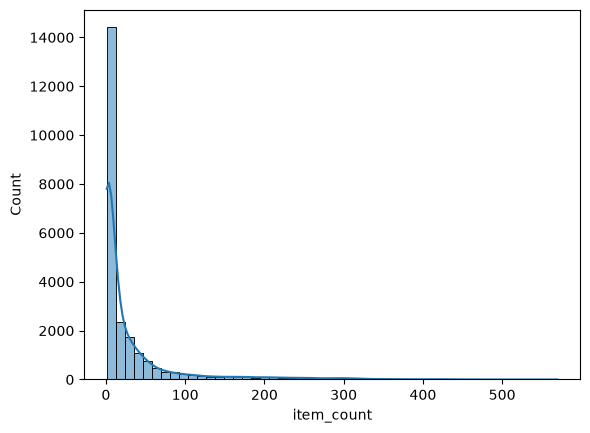

In [22]:
sns.histplot(sold['item_count'], kde=True, bins=50)
plt.show

In [23]:
sold['item_count'].quantile(0.99)

np.float64(301.0)

In [24]:
item_avg= df_sales.groupby('item_id')['item_count'].mean()
item_avg.sort_values(ascending=False).head(10)

item_id
19    215.635949
16     93.968978
76     55.696168
38     48.149635
9      40.031022
59     39.027372
4      31.422445
13     25.082117
56     21.750912
67     17.120438
Name: item_count, dtype: float64

In [25]:
df_items[df_items['id']==19]['name']

18    Strawberry Smoothy
Name: name, dtype: str

In [26]:
#strawberry smoothy is a most sold item

daily= df_sales.groupby('date')['item_count'].sum()

q1= daily.quantile(0.25)
q3= daily.quantile(0.75)
iqr= q3-q1

lower= q1- 1.5*iqr
upper= q3+ 1.5*iqr

daily_outliers= daily[(daily< lower)| (daily> upper)]
print(len(daily_outliers))

0


In [27]:
# there is no outliers are there in sales

In [28]:
# checking is there any duplicate items are there in item list

df_items.duplicated().sum()

np.int64(0)

In [29]:
df_items['id'].duplicated().sum()

np.int64(0)

In [30]:
df_items['name'].duplicated().sum()

np.int64(6)

In [31]:
same_name= df_items[df_items['name'].duplicated(keep=False)]
same_name.sort_values('name')

,id,store_id,name,kcal,cost
41,42,2,Fantastic Milky Smoothy,318,2.91
80,81,3,Fantastic Milky Smoothy,383,5.11
15,16,1,Frozen Milky Smoothy,284,3.21
70,71,5,Frozen Milky Smoothy,211,3.98
40,41,4,Milky Cake,624,6.01
72,73,1,Milky Cake,596,5.16
86,87,5,Milky Cake,627,7.22
71,72,4,Original Milky Cake,602,6.53
85,86,3,Original Milky Cake,595,6.50
51,52,3,Original Sweet Milky Soft Drink,535,5.68


In [32]:
# this is not a duplicate items. because each store have different product ids
# there are no outliers in the data set

In [33]:
# merging the data 

merged= df_sales.merge(df_items, left_on='item_id', right_on='id')
merged.head()

,date,item_id,price,item_count,id,store_id,name,kcal,cost
0,2019-01-01,3,29.22,2.0,3,1,Sweet Fruity Cake,931,29.22
1,2019-01-01,4,26.42,22.0,4,1,Amazing Steak Dinner with Rolls,763,26.42
2,2019-01-01,12,4.87,7.0,12,1,Fantastic Sweet Cola,478,4.87
3,2019-01-01,13,4.18,12.0,13,1,Sweet Frozen Soft Drink,490,4.18
4,2019-01-01,16,3.21,136.0,16,1,Frozen Milky Smoothy,284,3.21


In [34]:
merged= merged.rename(columns={'name': 'item_name'})
merged= merged.drop(columns=['id', 'cost'])
merged.head()

,date,item_id,price,item_count,store_id,item_name,kcal
0,2019-01-01,3,29.22,2.0,1,Sweet Fruity Cake,931
1,2019-01-01,4,26.42,22.0,1,Amazing Steak Dinner with Rolls,763
2,2019-01-01,12,4.87,7.0,1,Fantastic Sweet Cola,478
3,2019-01-01,13,4.18,12.0,1,Sweet Frozen Soft Drink,490
4,2019-01-01,16,3.21,136.0,1,Frozen Milky Smoothy,284


In [35]:
# rename the restaurants 

restaurants= df_resturants.rename(columns={'id' : 'store_id', 'name' : 'store_name'})
restaurants

,store_id,store_name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack
3,4,Fou Cher
4,5,Corner Cafe
5,6,Surfs Up


In [36]:
merged= merged.merge(restaurants, on='store_id')
merged.head()

,date,item_id,price,item_count,store_id,item_name,kcal,store_name
0,2019-01-01,3,29.22,2.0,1,Sweet Fruity Cake,931,Bob's Diner
1,2019-01-01,4,26.42,22.0,1,Amazing Steak Dinner with Rolls,763,Bob's Diner
2,2019-01-01,12,4.87,7.0,1,Fantastic Sweet Cola,478,Bob's Diner
3,2019-01-01,13,4.18,12.0,1,Sweet Frozen Soft Drink,490,Bob's Diner
4,2019-01-01,16,3.21,136.0,1,Frozen Milky Smoothy,284,Bob's Diner


In [37]:
merged.shape

(109600, 8)

In [38]:
merged['sales_amount']= merged['price'] * merged['item_count']
merged.head()

,date,item_id,price,item_count,store_id,item_name,kcal,store_name,sales_amount
0,2019-01-01,3,29.22,2.0,1,Sweet Fruity Cake,931,Bob's Diner,58.44
1,2019-01-01,4,26.42,22.0,1,Amazing Steak Dinner with Rolls,763,Bob's Diner,581.24
2,2019-01-01,12,4.87,7.0,1,Fantastic Sweet Cola,478,Bob's Diner,34.09
3,2019-01-01,13,4.18,12.0,1,Sweet Frozen Soft Drink,490,Bob's Diner,50.16
4,2019-01-01,16,3.21,136.0,1,Frozen Milky Smoothy,284,Bob's Diner,436.56


In [39]:
merged['year']= merged['date'].dt.year
merged['month']= merged['date'].dt.month
merged['day_name']= merged['date'].dt.day_name()
merged['quarter']= merged['date'].dt.quarter
merged.head()

,date,item_id,price,item_count,store_id,item_name,kcal,store_name,sales_amount,year,month,day_name,quarter
0,2019-01-01,3,29.22,2.0,1,Sweet Fruity Cake,931,Bob's Diner,58.44,2019,1,Tuesday,1
1,2019-01-01,4,26.42,22.0,1,Amazing Steak Dinner with Rolls,763,Bob's Diner,581.24,2019,1,Tuesday,1
2,2019-01-01,12,4.87,7.0,1,Fantastic Sweet Cola,478,Bob's Diner,34.09,2019,1,Tuesday,1
3,2019-01-01,13,4.18,12.0,1,Sweet Frozen Soft Drink,490,Bob's Diner,50.16,2019,1,Tuesday,1
4,2019-01-01,16,3.21,136.0,1,Frozen Milky Smoothy,284,Bob's Diner,436.56,2019,1,Tuesday,1


In [40]:
# 2.EDA

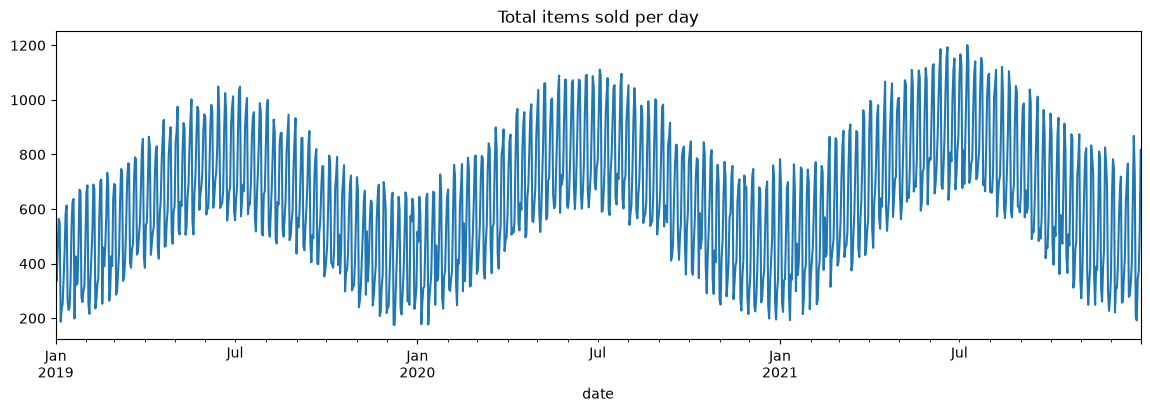

In [42]:
# overall sales pattern

daily= merged.groupby('date')['item_count'].sum()
daily.plot(figsize=(14,4), title='Total items sold per day')
plt.show()

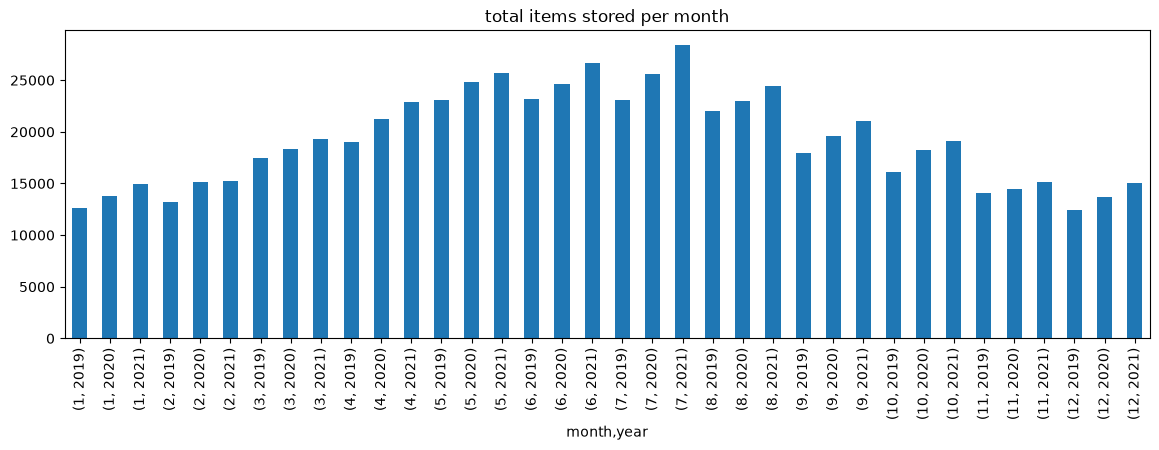

In [44]:
monthly= merged.groupby(['month', 'year'])['item_count'].sum()
monthly.plot(kind='bar', figsize=(14,4), title='total items stored per month')
plt.show()

In [48]:
# sales by day of the week

daily_df= merged.groupby(['date', 'day_name'])['item_count'].sum().reset_index()
daily_df.head()

,date,day_name,item_count
0,2019-01-01,Tuesday,427.0
1,2019-01-02,Wednesday,337.0
2,2019-01-03,Thursday,445.0
3,2019-01-04,Friday,564.0
4,2019-01-05,Saturday,552.0


In [53]:
day_order= ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day= daily_df.groupby('day_name')['item_count'].mean()
by_day= by_day.reindex(day_order)

by_day


day_name
Monday       449.435897
Tuesday      506.076433
Wednesday    562.407643
Thursday     744.885350
Friday       868.152866
Saturday     869.512821
Sunday       436.102564
Name: item_count, dtype: float64

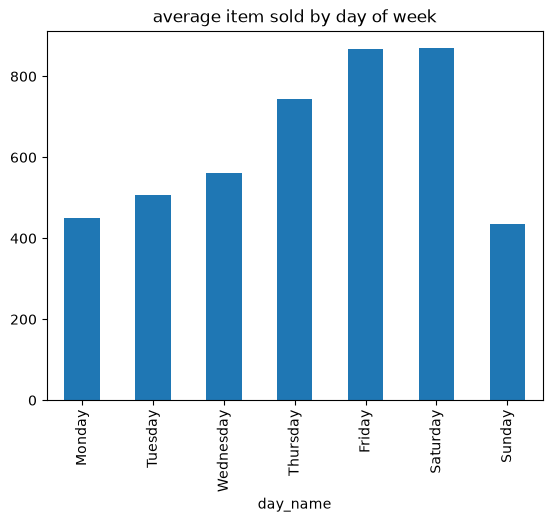

In [54]:
by_day.plot(kind='bar', title='average item sold by day of week')
plt.show()

In [55]:
# most of the sales are happening on saturday

In [56]:
# sales by month

daily_df2= merged.groupby(['date', 'month'])['item_count'].sum().reset_index()
by_month= daily_df2.groupby('month')['item_count'].mean()

by_month

month
1     443.763441
2     512.894118
3     592.870968
4     701.611111
5     791.741935
6     826.922222
7     829.301075
8     747.333333
9     651.777778
10    574.225806
11    485.222222
12    443.268817
Name: item_count, dtype: float64

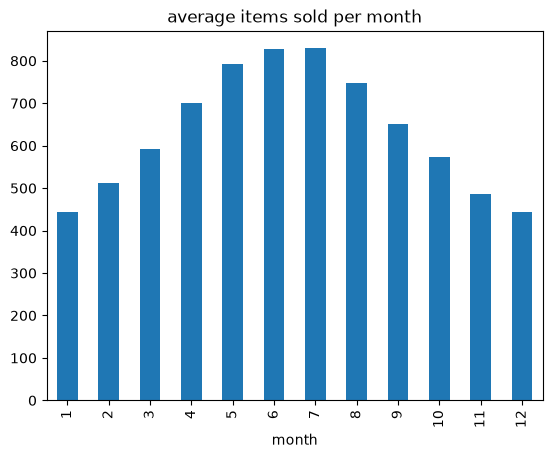

In [57]:
by_month.plot(kind='bar', title='average items sold per month')
plt.show()

In [58]:
# july month is the higher selling month

In [59]:
# sales by quarter

year_quarter= merged.groupby(['year', 'quarter'])['item_count'].sum().reset_index()
year_quarter

,year,quarter,item_count
0,2019,1,43231.0
1,2019,2,65259.0
2,2019,3,63152.0
3,2019,4,42595.0
4,2020,1,47278.0
5,2020,2,70654.0
6,2020,3,68241.0
7,2020,4,46408.0
8,2021,1,49494.0
9,2021,2,75287.0


In [60]:
by_quarter= year_quarter.groupby('quarter')['item_count'].mean()

by_quarter

quarter
1    46667.666667
2    70400.000000
3    68429.000000
4    46099.000000
Name: item_count, dtype: float64

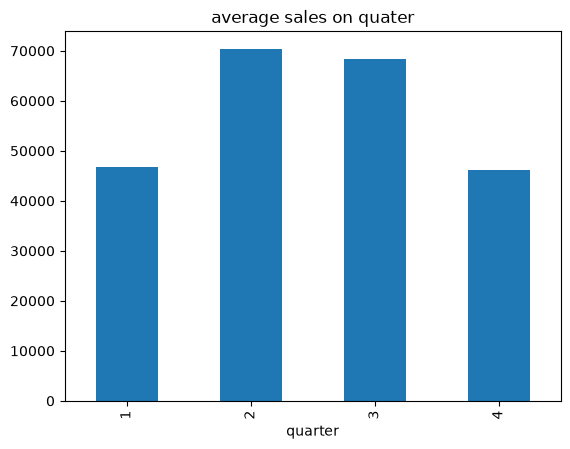

In [61]:
by_quarter.plot(kind='bar', title='average sales on quater')
plt.show()

In [65]:
# compare the restaurants

by_store= merged.groupby('store_name')['item_count'].sum().sort_values(ascending=False)

by_store

store_name
Bob's Diner       687527.0
Surfs Up            1803.0
Sweet Shack         1736.0
Corner Cafe         1310.0
Beachfront Bar      1305.0
Fou Cher            1106.0
Name: item_count, dtype: float64

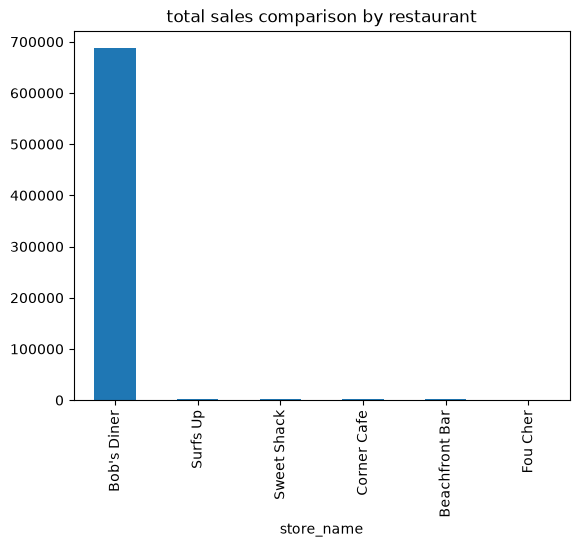

In [66]:
by_store.plot(kind='bar', title='total sales comparison by restaurant')
plt.show()

In [67]:
# compare the restaurants by year

store_year= merged.groupby(['store_name', 'year'])['item_count'].sum().unstack()
store_year

year,2019,2020,2021
store_name,,,
Beachfront Bar,439.0,437.0,429.0
Bob's Diner,211799.0,230191.0,245537.0
Corner Cafe,423.0,415.0,472.0
Fou Cher,392.0,357.0,357.0
Surfs Up,594.0,627.0,582.0
Sweet Shack,590.0,554.0,592.0


In [68]:
# compare restaurants by month

store_month= merged.groupby(['store_name', 'month'])['item_count'].sum().unstack()
store_month

month,1,2,3,4,5,6,7,8,9,10,11,12
store_name,,,,,,,,,,,,
Beachfront Bar,107.0,109.0,117.0,109.0,113.0,98.0,103.0,99.0,106.0,101.0,108.0,135.0
Bob's Diner,40672.0,43006.0,54510.0,62565.0,72988.0,73836.0,76528.0,68918.0,58064.0,52772.0,43085.0,40583.0
Corner Cafe,82.0,111.0,109.0,103.0,107.0,119.0,111.0,113.0,112.0,124.0,109.0,110.0
Fou Cher,109.0,72.0,96.0,92.0,110.0,84.0,81.0,78.0,81.0,98.0,96.0,109.0
Surfs Up,132.0,170.0,155.0,146.0,156.0,138.0,161.0,162.0,143.0,160.0,141.0,139.0
Sweet Shack,168.0,128.0,150.0,130.0,158.0,148.0,141.0,132.0,154.0,148.0,131.0,148.0


In [72]:
# by day of week

store_day= merged.groupby(['store_name', 'day_name'])['item_count'].sum().unstack()

store_day[day_order]


day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
store_name,,,,,,,
Beachfront Bar,188.0,188.0,207.0,180.0,176.0,186.0,180.0
Bob's Diner,69086.0,78405.0,87274.0,115922.0,135238.0,134602.0,67000.0
Corner Cafe,183.0,199.0,170.0,184.0,193.0,181.0,200.0
Fou Cher,155.0,143.0,171.0,161.0,167.0,153.0,156.0
Surfs Up,256.0,244.0,248.0,254.0,289.0,258.0,254.0
Sweet Shack,244.0,275.0,228.0,246.0,237.0,264.0,242.0


In [73]:
# most popular items

popular= merged.groupby(['item_name', 'store_name'])['item_count'].sum().reset_index()
popular= popular.sort_values('item_count', ascending=False)

popular.head(10)

,item_name,store_name,item_count
91,Strawberry Smoothy,Bob's Diner,236337.0
47,Frozen Milky Smoothy,Bob's Diner,102990.0
9,Amazing pork lunch,Bob's Diner,61043.0
68,Mutton Dinner,Bob's Diner,52772.0
71,Orange Juice,Bob's Diner,43874.0
22,Blue Ribbon Beef Entree,Bob's Diner,42774.0
4,Amazing Steak Dinner with Rolls,Bob's Diner,34439.0
94,Sweet Frozen Soft Drink,Bob's Diner,27490.0
89,Sea Bass with Vegetables Dinner,Bob's Diner,23839.0
96,Sweet Lamb Cake,Bob's Diner,18764.0


In [74]:
# most popular item at each store

top_per_store= popular.drop_duplicates(subset='store_name')
top_per_store

,item_name,store_name,item_count
91,Strawberry Smoothy,Bob's Diner,236337.0
16,Awesome Smoothy,Sweet Shack,1692.0
40,Fantastic Milky Smoothy,Beachfront Bar,1147.0
17,Awesome Soft Drink,Surfs Up,997.0
27,Blue Ribbon Fruity Vegi Lunch,Fou Cher,298.0
48,Frozen Milky Smoothy,Corner Cafe,273.0


In [75]:
daily_sales= merged.groupby('date')['item_count'].sum().reset_index()
print(daily_sales.shape)
daily_sales.head()

(1096, 2)


,date,item_count
0,2019-01-01,427.0
1,2019-01-02,337.0
2,2019-01-03,445.0
3,2019-01-04,564.0
4,2019-01-05,552.0


In [77]:
# create date features

daily_sales['year']= daily_sales['date'].dt.year
daily_sales['month']= daily_sales['date'].dt.month
daily_sales['quarter']= daily_sales['date'].dt.quarter
daily_sales['day_of_month']= daily_sales['date'].dt.day
daily_sales['day_of_week']= daily_sales['date'].dt.dayofweek
daily_sales['day_of_year']= daily_sales['date'].dt.dayofyear
daily_sales.head(10)

/tmp/ipykernel_10248/3047765547.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily_sales['day_of_week']= daily_sales['date'].dt.dayofweek
/tmp/ipykernel_10248/3047765547.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  daily_sales['day_of_year']= daily_sales['date'].dt.dayofyear


,date,item_count,year,month,quarter,day_of_month,day_of_week,day_of_year
0,2019-01-01,427.0,2019,1,1,1,1,1
1,2019-01-02,337.0,2019,1,1,2,2,2
2,2019-01-03,445.0,2019,1,1,3,3,3
3,2019-01-04,564.0,2019,1,1,4,4,4
4,2019-01-05,552.0,2019,1,1,5,5,5
5,2019-01-06,187.0,2019,1,1,6,6,6
6,2019-01-07,232.0,2019,1,1,7,0,7
7,2019-01-08,254.0,2019,1,1,8,1,8
8,2019-01-09,346.0,2019,1,1,9,2,9
9,2019-01-10,452.0,2019,1,1,10,3,10


In [78]:
# split the data: last 6 months data is a test data

train= daily_sales[daily_sales['date']< '2021-07-01']
test= daily_sales[daily_sales['date']>= '2021-07-01']

train.shape, test.shape

((912, 8), (184, 8))

In [79]:
# seperate input and output

features= ['year', 'month', 'quarter', 'day_of_month', 'day_of_week','day_of_year']

X_train= train[features]
y_train= train['item_count']

X_test= test[features]
y_test= test['item_count']

In [80]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

In [81]:
# train 3 models

lr= LinearRegression()
lr.fit(X_train, y_train)
lr_pred= lr.predict(X_test)


lr_rmse= np.sqrt(mean_squared_error(y_test, lr_pred))
lr_rmse

np.float64(244.1987036370602)

In [82]:
# random forest

rf= RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred= rf.predict(X_test)

rf_rmse= np.sqrt(mean_squared_error(y_test, rf_pred))
rf_rmse

np.float64(62.5436505874445)

In [83]:
# xg boost

xgb= XGBRegressor(n_estimators= 500, random_state=42, learning_rate=0.05)
xgb.fit(X_train, y_train)
xgb_pred= xgb.predict(X_test)

xgb_rmse= np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_rmse

np.float64(60.737299486117024)

In [84]:
# forcast the next year

future= pd.DataFrame({'date': pd.date_range('2022-01-01', '2022-12-31')})
future.shape

(365, 1)

In [85]:
# add the features to the dataframe

future['year']= future['date'].dt.year
future['month']= future['date'].dt.month
future['quarter']= future['date'].dt.quarter
future['day_of_month']= future['date'].dt.day
future['day_of_week']= future['date'].dt.dayofweek
future['day_of_year']= future['date'].dt.dayofyear
future.head()

/tmp/ipykernel_10248/771549040.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  future['day_of_week']= future['date'].dt.dayofweek
/tmp/ipykernel_10248/771549040.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  future['day_of_year']= future['date'].dt.dayofyear


,date,year,month,quarter,day_of_month,day_of_week,day_of_year
0,2022-01-01,2022,1,1,1,5,1
1,2022-01-02,2022,1,1,2,6,2
2,2022-01-03,2022,1,1,3,0,3
3,2022-01-04,2022,1,1,4,1,4
4,2022-01-05,2022,1,1,5,2,5


In [86]:
# re-training the best model with full data

best_model= XGBRegressor(n_estimators= 500, learning_rate=0.05, random_state= 42)
best_model.fit(daily_sales[features], daily_sales['item_count'])

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [87]:
future['predicted_sales']= best_model.predict(future[features])
future.head()

,date,year,month,quarter,day_of_month,day_of_week,day_of_year,predicted_sales
0,2022-01-01,2022,1,1,1,5,1,737.127869
1,2022-01-02,2022,1,1,2,6,2,307.824982
2,2022-01-03,2022,1,1,3,0,3,244.757431
3,2022-01-04,2022,1,1,4,1,4,316.520721
4,2022-01-05,2022,1,1,5,2,5,354.796997


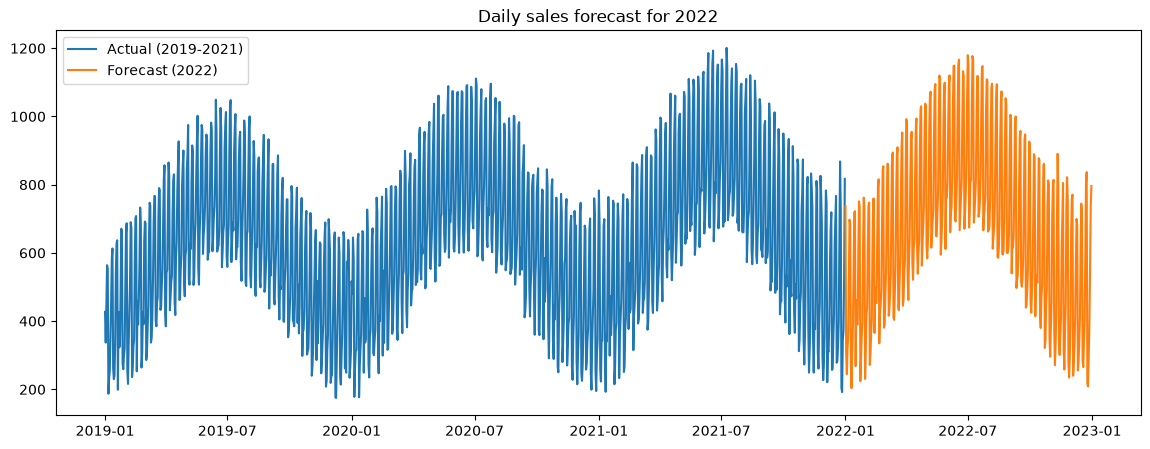

In [88]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales['date'], daily_sales['item_count'], label='Actual (2019-2021)')
plt.plot(future['date'], future['predicted_sales'], label='Forecast (2022)')
plt.legend()
plt.title('Daily sales forecast for 2022')
plt.show()